In [ ]:
!pip install bertopic --quiet
!pip install Sastrawi --quiet
!pip install gensim --quiet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
import warnings
from gensim.models.coherencemodel import CoherenceModel
from gensim.corpora.dictionary import Dictionary
warnings.filterwarnings('ignore')

In [ ]:
# Load data
df = pd.read_csv('/content/data_final_25_destinasi_with_coords.csv')

In [ ]:
# Clean data by dropping NaN reviews
df_clean = df.dropna(subset=["Teks Ulasan Bahasa Indonesia"]).reset_index(drop=True)
input_docs = df_clean["Teks Ulasan Bahasa Indonesia"].str.lower().reset_index(drop=True)

# Opsional: Filter docs yang relevan dengan sustainable tourism (uncomment jika ingin)
sustainable_terms = ['berkelanjutan', 'lingkungan', 'pelestarian', 'konservasi', 'ramah', 'budaya', 'lokal', 'ekonomi']
input_docs = input_docs[input_docs.str.contains('|'.join(sustainable_terms))]

print(f"Teks Ulasan Indonesia (setelah filter jika aktif): {len(input_docs)}")

Teks Ulasan Indonesia (setelah filter jika aktif): 9469


In [ ]:
# Get Sastrawi stop words for Indonesian
sastrawi_factory = StopWordRemoverFactory()
indonesian_stop_words = sastrawi_factory.get_stop_words()

In [ ]:
# Get unique destination names and split into individual words to exclude them as keywords
destinations = df_clean['Destinasi Wisata'].unique()
destination_words = set()
for dest in destinations:
    destination_words.update(dest.lower().split())  # Split multi-word destinations into words

In [ ]:
# Daftar stop words yang diperluas, tapi hilangkan kata terkait sustainable
common_nouns = [
    'anak', 'gadis', 'individu', 'wanita', 'perempuan', 'gunung', 'laut', 'sungai', 'bis', 'tas', 'payung', 'gelas', 'botol',
    'ayah', 'adik', 'acara', 'akun', 'area', 'benda', 'tempat', 'makanan', 'tumbuhan', 'seng', 'pin', 'ibu', 'kota', 'negara',
    'orang', 'fungsi', 'meja', 'kursi', 'rumah', 'jalan', 'mobil', 'sepeda', 'pesawat', 'kapal', 'museum'
]

animal_names = [
    'ayam', 'angsa', 'anakonda', 'dinosaurus', 'domba', 'dugong', 'gajah', 'gagak', 'anjing', 'anoa', 'babi', 'badak',
    'bebek', 'buaya', 'beruang', 'burung', 'bunglon', 'bintang laut', 'antelop', 'biawak', 'kadal', 'komodo', 'ular',
    'katak', 'kodok', 'kura-kura', 'penyu', 'merpati', 'bekicot', 'belalang', 'belatung', 'arwana', 'belibis', 'monyet'
]

neutral_words = [
    'hari', 'waktu', 'jam', 'tahun', 'bulan', 'minggu', 'nomor', 'angka', 'buku', 'kertas', 'pohon', 'daun', 'bunga',
    'buah', 'air', 'tanah', 'api', 'angin', 'desa', 'kota', 'jalan', 'ruang', 'lantai', 'dinding', 'atap',
    'cahaya', 'gelap', 'panas', 'dingin', 'udara', 'langit', 'awan', 'hujan', 'matahari', 'bulan', 'bintang', 'bumi',
    # Hilangkan 'alam', 'lahan', dll. yang relevan
    'sawah', 'ladang', 'hutan', 'pantai', 'pulau', 'teluk', 'sumber', 'mata air', 'kolam', 'danau',
    'gedung', 'bangunan', 'pintu', 'jendela', 'tangga', 'lorong', 'kamar', 'halaman', 'taman', 'kebun', 'trotoar',
    'aspal', 'batu', 'pasir', 'kerikil', 'tanaman', 'akar', 'ranting', 'batang', 'biji', 'benih', 'warna', 'bentuk',
    'ukuran', 'panjang', 'lebar', 'tinggi', 'berat', 'ringan', 'besar', 'kecil', 'luas', 'sempit', 'dalam', 'dangkal',
    'tebal', 'tipis', 'bulat', 'kotak', 'segitiga', 'lingkaran', 'garis', 'titik', 'sudut', 'permukaan', 'bagian',
    'sisi', 'tepi', 'pusat', 'tengah', 'pinggir'
]

additional_stop_words = [
    # Kata hubung, sambung, dll. (tetap, karena netral)
    'dan', 'serta', 'atau', 'tetapi', 'namun', 'melainkan', 'sedangkan', 'sebaliknya',
    'karena', 'sebab', 'maka', 'sehingga', 'akibatnya', 'oleh karena itu', 'lantaran',
    'jika', 'kalau', 'bila', 'apabila', 'jikalau', 'asalkan', 'selama', 'sebelum',
    'sesudah', 'setelah', 'ketika', 'saat', 'manakala', 'sementara', 'supaya',
    'agar', 'untuk', 'demi', 'guna', 'meskipun', 'walaupun', 'kendati', 'biarpun',
    'padahal', 'yaitu', 'yakni', 'bahwa', 'seperti', 'sebagai', 'ibarat', 'umpama',
    'misalnya', 'contohnya',
    'yang', 'ini', 'itu', 'tersebut', 'tadi', 'demikian', 'begitu', 'tersebut',
    'di', 'ke', 'dari', 'pada', 'dalam', 'antara', 'dengan', 'oleh', 'kepada',
    'terhadap', 'tentang', 'mengenai', 'atas', 'bawah', 'depan', 'belakang',
    'samping', 'luar', 'dalam', 'sekitar', 'bersama', 'tanpa', 'menuju', 'hingga',
    'sampai', 'kecuali', 'selain',
    'ber', 'me', 'men', 'meng', 'meny', 'ter', 'per', 'pe', 'an', 'kan', 'i',
    'nya', 'ku', 'mu', 'kami', 'kita', 'mereka', 'ia', 'dia', 'beliau',
    'keber', 'kemen', 'keter', 'sepe', 'pem', 'pen', 'peng', 'peny', 'diper',
    'dipe', 'dike', 'dimen', 'dimeng', 'diter', 'diper', 'berpe', 'berpen',
    'berpeng', 'berpeny', 'terpe', 'terpen', 'terpeng', 'terpeny',
    'ada', 'adalah', 'ialah', 'terdapat', 'terjadi', 'berlangsung', 'sedang',
    'telah', 'sudah', 'belum', 'akan', 'bisa', 'dapat', 'mampu', 'harus',
    'perlu', 'mungkin', 'barangkali', 'seharusnya', 'semestinya', 'pasti',
    'tentu', 'mesti', 'lagi', 'masih', 'sudah', 'tadi', 'kemudian', 'lalu',
    'selanjutnya', 'berikutnya', 'sekarang', 'kini', 'nanti', 'kemarin',
    'besok', 'sesudahnya', 'sebelumnya', 'umumnya', 'biasanya', 'sering',
    'kadang', 'jarang', 'selalu', 'setiap', 'tiap', 'beberapa', 'banyak',
    'sedikit', 'cukup', 'lebih', 'kurang', 'hampir', 'sekitar', 'kira-kira'
]

verb_stop_words = [
    # Kata kerja dasar dan imbuhan (tetap, tapi hilangkan jika konflik dengan sustainable)
    'jalan', 'lari', 'duduk', 'berdiri', 'tidur', 'bangun', 'makan', 'minum',
    'lihat', 'dengar', 'bicara', 'berbicara', 'katakan', 'bilang',
    'tulis', 'baca', 'hitung', 'pikir', 'berpikir', 'rasa', 'merasa', 'tahu',
    'ketahui', 'ingat', 'lupa', 'jalani', 'hidup', 'mati', 'datang', 'pergi',
    'pulang', 'masuk', 'keluar', 'naik', 'turun', 'buka', 'tutup', 'ambil',
    'beri', 'tarik', 'dorong', 'angkat', 'bawa', 'letak', 'taruh', 'lempar',
    'tangkap', 'tendang', 'pukul', 'tunjuk', 'cari', 'temukan',
    'hilang', 'tanya', 'jawab', 'panggil', 'hubungi', 'kirim', 'terima',
    'tunggu', 'mulai', 'selesai', 'henti', 'berhenti', 'lanjut', 'teruskan',
    'ulang', 'kembali', 'laksanakan', 'jalankan', 'kerjakan', 'buat', 'bikin',
    'cipta', 'hasilkan', 'ubah', 'ganti', 'pindah', 'geser', 'atur', 'susun',
    'berjalan', 'berlari', 'duduki', 'berdirikan', 'tiduri', 'bangunkan',
    'memakan', 'meminum', 'melihat', 'mendengar', 'mengatakan', 'menulis',
    'membaca', 'menghitung', 'memikirkan', 'merasa', 'mengetahui', 'mengingat',
    'melupakan', 'menjalani', 'menghidupkan', 'mematikan', 'mendatangi',
    'meninggalkan', 'memasuki', 'mengeluarkan', 'menaiki', 'menurunkan',
    'membuka', 'menutup', 'mengambil', 'memberikan', 'menarik', 'mendorong',
    'mengangkat', 'membawa', 'meletakkan', 'melempar', 'menangkap', 'menendang',
    'memukul', 'menunjukkan', 'mencari', 'menemukan', 'menghilangkan',
    'bertanya', 'menjawab', 'memanggil', 'menghubungi', 'mengirim', 'menerima',
    'menunggu', 'memulai', 'menyelesaikan', 'menghentikan', 'melanjutkan',
    'mengulang', 'mengembalikan', 'melaksanakan', 'menjalankan', 'mengerjakan',
    'membuat', 'menciptakan', 'menghasilkan', 'mengubah', 'mengganti',
    'memindahkan', 'mengatur', 'menyusun',
    'sedang berjalan', 'sudah selesai', 'akan datang', 'telah pergi',
    'sedang makan', 'baru mulai', 'ingin tahu', 'coba lihat', 'pernah dengar',
    'mau pulang', 'sedang duduk', 'akan berbicara', 'telah menulis',
    'sedang membaca', 'coba pikir', 'rasa ingin', 'tahu pasti', 'ingat kembali',
    'lupa seketika', 'jalani hidup', 'datang tiba-tiba', 'pergi diam-diam',
    'masuk perlahan', 'keluar cepat', 'naik tangga', 'turun bukit', 'buka pintu',
    'tutup jendela', 'ambil kesempatan', 'beri perhatian', 'tarik nafas',
    'dorong pintu', 'angkat beban', 'bawa pulang', 'letakkan di', 'lempar jauh',
    'tangkap bola', 'tendang keras', 'pukul ringan', 'tunjuk arah', 'cari tahu',
    'temukan jawaban', 'hilang tiba-tiba', 'tanya langsung', 'jawab singkat',
    'panggil nama', 'hubungi segera', 'kirim pesan', 'terima kasih',
    'tunggu sebentar', 'mulai sekarang', 'selesai tepat', 'henti sejenak',
    'lanjut besok', 'ulang lagi', 'kembali pulang', 'laksanakan tugas',
    'jalankan rencana', 'kerjakan proyek', 'buat baru', 'cipta karya',
    'hasilkan keuntungan', 'ubah rencana', 'ganti posisi', 'pindah tempat',
    'geser sedikit', 'atur ulang', 'susun rapi'
]

additional_verb_stop_words = [
    'menyelam', 'terjaga', 'mengikuti', 'menantang', 'menceritakan', 'menjadi',
    'menanjak', 'menawarkan', 'terbayar', 'menginap', 'bersantai', 'terlupakan',
    'menyengat',
    'menyelami', 'menjaga', 'mengikuti', 'menantang', 'menceritakan', 'menjadikan',
    'menanjaki', 'menawarkan', 'membayar', 'menginapi', 'bersantai', 'melupakan',
    'menyengat',
    'sedang menyelam', 'tetap terjaga', 'terus mengikuti', 'menantang diri',
    'menceritakan kisah', 'menjadi bagian', 'sedang menanjak', 'menawarkan bantuan',
    'terbayar lunas', 'menginap semalam', 'bersantai santai', 'terlupakan begitu',
    'menyengat hidung', 'sayangnya terjadi', 'pendakiannya dimulai', 'beragam aktivitas',
    'peselancar beraksi', 'liburan seru', 'kembali lagi', 'bintang bersinar',
    'tapi', 'jadi', 'terutama', 'beberapa', 'perjuangan', 'pecinta', 'salah',
    'sayangnya', 'pendakiannya', 'belerang', 'beragam', 'peselancar', 'liburan',
    'bintang','1765', 'banget', 'foto', 'jogja', 'kesini', 'buatan', 'keraton', 'tamansari',
    '1758', 'hamengku', 'terlewatkan', 'jangan', 'terlewat', 'menepati', 'kau', 'manalaan', 'tukazzibaan',
    'sejarah', 'pelajari', 'belajar', 'mempelajari', 'sini','yogyakarta','kompleks','ngayogyakarta','1758','kedhaton',
    'wajib','dicoba','berada','baik','semuanya','dijanjikan', 'kurasa','diserang','tolak','allah','munkat','alaaa','robbikuma','dikunjungi','000','dilihat','takut',
    'sultan','dibangun','bekas','pesanggrahan','sisa','melewatkannya','rabies','mampir','bahkan','mana','ayyi','manakah','fa','sangat','yg','hewan','hindu',
    'merupakan','menikmati','kapur','kolonial','kurangnya','merupakan','berbagai',
    'imax','soeharto','provinsi','ubud','ekor','monkey','forest','monkey forest','ekor panjang','biasa',
    'semua','sarung','satu','terbenam','sebuah','daerah','kera','kelompok kelompok','panjang','perlindungan','terletak', 'anjungan','padangtegal','utama','1975','57','stupa','syailendra','ga','mau','kl','kt','sy','krn','sama','udah','krn'.'wanti'
]


In [ ]:
# Protect sustainable keywords
sustainable_keywords = ['berkelanjutan', 'lingkungan', 'sosial', 'ekonomi', 'pelestarian', 'konservasi', 'ramah', 'kelestarian', 'budaya', 'masyarakat', 'lokal', 'komunitas', 'dampak', 'jangka', 'panjang', 'wisata', 'tourism', 'sustainable']
lists_to_check = [indonesian_stop_words, common_nouns, animal_names, neutral_words, additional_stop_words, verb_stop_words, additional_verb_stop_words]
for lst in lists_to_check:
    for word in sustainable_keywords:
        if word in lst:
            lst.remove(word)

In [ ]:
# Combine all into custom stop words
custom_stop_words = list(set(indonesian_stop_words + list(destination_words) + common_nouns + animal_names + neutral_words + additional_stop_words + verb_stop_words + additional_verb_stop_words))

In [ ]:
embedding_model = SentenceTransformer("intfloat/multilingual-e5-large")
embeddings = embedding_model.encode(input_docs.tolist(), show_progress_bar=True)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-large
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/296 [00:00<?, ?it/s]

In [ ]:
# Pre-reduce embeddings for clustering evaluation
umap_for_clustering = UMAP(n_neighbors=5, n_components=10, min_dist=0.0, metric='cosine', random_state=42)
reduced_embeddings_clustering = umap_for_clustering.fit_transform(embeddings)

In [ ]:
# Pre-reduce embeddings for visualization (2D)
reduced_embeddings = UMAP(n_neighbors=5, n_components=2, min_dist=0.0, metric='cosine', random_state=42).fit_transform(embeddings)

In [ ]:
# Fungsi untuk silhouette score (tetap)
def calculate_silhouette_scores(embeddings, min_topics=5, max_topics=25):
    silhouette_scores = []
    topic_range = range(min_topics, max_topics + 1)
    for n_topics in topic_range:
        kmeans = KMeans(n_clusters=n_topics, random_state=42, n_init=10)
        cluster_labels = kmeans.fit_predict(embeddings)
        score = silhouette_score(embeddings, cluster_labels)
        silhouette_scores.append(score)
    return topic_range, silhouette_scores

In [ ]:
def plot_silhouette_scores(topic_range, silhouette_scores):
    plt.figure(figsize=(12, 6))
    plt.plot(topic_range, silhouette_scores, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Topics')
    plt.ylabel('Silhouette Score')
    plt.title('Silhouette Score vs Number of Topics')
    plt.grid(True, alpha=0.3)
    optimal_idx = np.argmax(silhouette_scores)
    optimal_topics = topic_range[optimal_idx]
    optimal_score = silhouette_scores[optimal_idx]
    plt.axvline(x=optimal_topics, color='r', linestyle='--', alpha=0.7)
    plt.annotate(f'Optimal: {optimal_topics} topics\nScore: {optimal_score:.4f}',
                 xy=(optimal_topics, optimal_score),
                 xytext=(optimal_topics + 2, optimal_score + 0.01),
                 arrowprops=dict(arrowstyle='->', color='red'),
                 fontsize=12, color='red')
    plt.tight_layout()
    plt.show()
    return optimal_topics, optimal_score

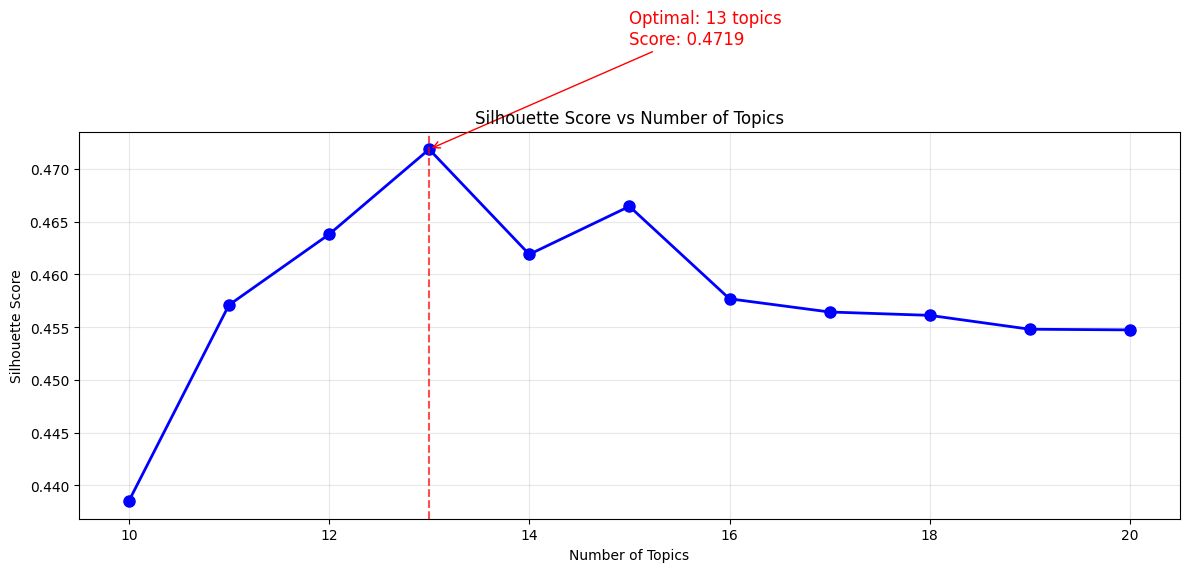

Optimal number of topics: 13
Best silhouette score: 0.4719


In [ ]:
topic_range, silhouette_scores = calculate_silhouette_scores(reduced_embeddings_clustering, min_topics=10, max_topics=20)
optimal_topics, optimal_score = plot_silhouette_scores(topic_range, silhouette_scores)

print(f"Optimal number of topics: {optimal_topics}")
print(f"Best silhouette score: {optimal_score:.4f}")

In [ ]:
# Set up models
umap_model = UMAP(n_neighbors=5, n_components=5, min_dist=0.0, metric='cosine', random_state=42)
hdbscan_model = HDBSCAN(min_cluster_size=5, metric='euclidean', cluster_selection_method='eom', prediction_data=True)

In [ ]:
# Representation models (tetap, tapi bisa tambah jika perlu)
keybert = KeyBERTInspired()
mmr = MaximalMarginalRelevance(diversity=0.3)
representation_model = {"KeyBERT": keybert, "MMR": mmr}

In [ ]:
# Custom vectorizer: Tambah ngram_range=(1,2) untuk frasa seperti "ramah lingkungan"
vectorizer_model = CountVectorizer(stop_words=custom_stop_words, ngram_range=(1, 2))

In [ ]:
# Seed topics untuk guided modeling (fokus sustainable tourism)
seed_topics = [
    ["lingkungan", "pelestarian", "konservasi", "ramah lingkungan", "kebersihan", "alam lestari", "reduce waste"],
    ["sosial", "budaya", "masyarakat lokal", "komunitas", "inklusif", "tradisi", "partisipasi masyarakat"],
    ["ekonomi", "berkelanjutan", "pekerjaan lokal", "pendapatan", "dukungan ekonomi", "jangka panjang"],
    ["wisata berkelanjutan", "sustainable tourism", "dampak positif", "kelestarian", "pariwisata ramah"]
]

In [ ]:
# Flatten untuk ctfidf
seed_words = [word for sublist in seed_topics for word in sublist]

In [ ]:
# Guided c-tf-idf model
ctfidf_model = ClassTfidfTransformer(seed_words=seed_words, seed_multiplier=2)

In [ ]:
# Create BERTopic dengan guided
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    representation_model=representation_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,  # Guidance utama
    nr_topics=optimal_topics,   # Atau 'auto' jika ingin fleksibel
    top_n_words=15,             # Lebih banyak keyword untuk deskripsi sustainable
    verbose=True
)

In [ ]:
# Train model
topics, probs = topic_model.fit_transform(input_docs, embeddings)

2026-02-10 09:51:25,098 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-02-10 09:51:37,720 - BERTopic - Dimensionality - Completed ✓
2026-02-10 09:51:37,721 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-02-10 09:51:38,185 - BERTopic - Cluster - Completed ✓
2026-02-10 09:51:38,187 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-02-10 09:51:40,110 - BERTopic - Representation - Completed ✓
2026-02-10 09:51:40,115 - BERTopic - Topic reduction - Reducing number of topics
2026-02-10 09:51:40,149 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-02-10 09:53:17,225 - BERTopic - Representation - Completed ✓
2026-02-10 09:53:17,233 - BERTopic - Topic reduction - Reduced number of topics from 379 to 13


In [ ]:
# Final silhouette score
final_silhouette = silhouette_score(reduced_embeddings_clustering, topics)
print(f"Final model silhouette score: {final_silhouette:.4f}")

Final model silhouette score: -0.5325


In [ ]:
# Get topic info
topic_info = topic_model.get_topic_info()
print(topic_info)
topic_info.to_csv('topic_info_sustainable.csv', index=False)

    Topic  Count                                             Name  \
0      -1   2948                 -1_budaya_ramah_lingkungan_bagus   
1       0   4121                  0_ramah_lokal_lingkungan_budaya   
2       1   1102                       1_tiket_pemandu_kuil_benar   
3       2    657          2_budaya_pemandangan_menakjubkan_buddha   
4       3    491             3_budaya_tmii_warisan_warisan budaya   
5       4     68                      4_kawah_jeep_sunrise_terbit   
6       5     30                5_ramah_petugas_guide ramah_guide   
7       6     15            6_tebing_pemandangan_jernih_destinasi   
8       7     13                    7_tmii_budaya_teater_miniatur   
9       8      7  8_kelompok_kelompok kelompok_konservasi_panjang   
10      9      6         9_budaya_cagar budaya_budaya cagar_cagar   
11     10      6                 10_utk_beli_30rb_dapatkan gelang   
12     11      5           11_ktp_asing_memperlakukan_resepsionis   

                                 

In [ ]:
texts = [doc.split() for doc in input_docs]  # Tokenize dokumen
dictionary = Dictionary(texts)

In [ ]:
topics_gensim = []
for topic_num in topic_info['Topic'].unique():
    if topic_num != -1:
        topic_words = [word for word, _ in topic_model.get_topic(topic_num)]
        topics_gensim.append(topic_words)

cm = CoherenceModel(topics=topics_gensim, texts=texts, dictionary=dictionary, coherence='c_v')
coherence_cv = cm.get_coherence()
print(f"Topic Coherence (C_V): {coherence_cv:.4f}")

Topic Coherence (C_V): 0.4956


In [ ]:
# Opsional: Hitung per topic
per_topic_coherence = cm.get_coherence_per_topic()
for i, score in enumerate(per_topic_coherence):
    print(f"Topic {i}: Coherence {score:.4f}")

Topic 0: Coherence 0.2673
Topic 1: Coherence 0.2057
Topic 2: Coherence 0.5394
Topic 3: Coherence 0.4437
Topic 4: Coherence 0.7730
Topic 5: Coherence 0.4782
Topic 6: Coherence 0.6664
Topic 7: Coherence 0.8668
Topic 8: Coherence 0.4469
Topic 9: Coherence 0.5016
Topic 10: Coherence 0.3548
Topic 11: Coherence 0.4030


In [ ]:
# Jika ingin U_Mass
cm_umass = CoherenceModel(topics=topics_gensim, texts=texts, dictionary=dictionary, coherence='u_mass')
coherence_umass = cm_umass.get_coherence()
print(f"Topic Coherence (U_Mass): {coherence_umass:.4f}")

Topic Coherence (U_Mass): -4.4226


In [ ]:
# Document info
doc_info = topic_model.get_document_info(input_docs)
# Align 'Destinasi Wisata' with the filtered input_docs by using the index of input_docs
doc_info['Destinasi Wisata'] = df_clean.loc[input_docs.index, 'Destinasi Wisata'].values
print("\nDocument Info:")
print(doc_info)


Document Info:
                                               Document  Topic  \
0     menurutku ini tempat terbaik di ubud untuk dik...     -1   
1     tempat yang bagus untuk kunjungan singkat, aga...      0   
2     bagus, hutan yang penuh dengan monyet.\ntentu ...      0   
3     salah satu tempat yang bagus untuk dikunjungi ...      0   
4     anda tidak akan melihat sesuatu yang tak terlu...     -1   
...                                                 ...    ...   
9464  senang bisa mampir kesini dan bisa bantu ekono...     -1   
9465  pantai yg memang menyembuhkan mata dari penatn...     -1   
9466          orang-orangnya ramah dan tempatnya indah.      0   
9467                                zona ekonomi khusus      3   
9468  pengalaman 5 hari yang luar biasa di kapal pes...      3   

                                      Name  \
0         -1_budaya_ramah_lingkungan_bagus   
1          0_ramah_lokal_lingkungan_budaya   
2          0_ramah_lokal_lingkungan_budaya   
3      

In [ ]:
# Fungsi distribusi (tetap)
def get_topic_distribution(topic_model, input_docs):
    doc_info = topic_model.get_document_info(input_docs)
    if 'Topic' not in doc_info.columns:
        raise ValueError("The output from topic_model must contain 'Topic' column.")
    topic_counts = doc_info['Topic'].value_counts().sort_index()
    total_docs = len(doc_info)
    total_docs_wo_noise = len(doc_info[doc_info['Topic'] != -1])
    topic_keywords = {}
    for topic_id in topic_counts.index:
        if topic_id != -1:
            topic_words = topic_model.get_topic(topic_id)
            if topic_words:
                topic_keywords[topic_id] = ", ".join([word for word, _ in topic_words[:5]])
            else:
                topic_keywords[topic_id] = "No keywords"
        else:
            topic_keywords[topic_id] = "Noise/Outliers"
    summary = pd.DataFrame({
        'Topic': topic_counts.index,
        'n_doc': topic_counts.values,
        'percentage': (topic_counts.values / total_docs) * 100,
        'keywords': [topic_keywords.get(topic_id, "No keywords") for topic_id in topic_counts.index]
    })
    summary['percentage_wo_noise'] = summary.apply(
        lambda row: (row['n_doc'] / total_docs_wo_noise * 100) if row['Topic'] != -1 else 0,
        axis=1
    )
    return summary

summary = get_topic_distribution(topic_model, input_docs)
summary.to_csv('topic_distribution_summary_sustainable.csv', index=False)
print("Topic distribution summary saved to topic_distribution_summary_sustainable.csv")
print(summary)

Topic distribution summary saved to topic_distribution_summary_sustainable.csv
    Topic  n_doc  percentage  \
0      -1   2948   31.133171   
1       0   4121   43.520963   
2       1   1102   11.637977   
3       2    657    6.938431   
4       3    491    5.185342   
5       4     68    0.718133   
6       5     30    0.316823   
7       6     15    0.158412   
8       7     13    0.137290   
9       8      7    0.073925   
10      9      6    0.063365   
11     10      6    0.063365   
12     11      5    0.052804   

                                             keywords  percentage_wo_noise  
0                                      Noise/Outliers             0.000000  
1             ramah, lokal, lingkungan, budaya, bagus            63.195829  
2                 tiket, pemandu, kuil, benar, budaya            16.899249  
3   budaya, pemandangan, menakjubkan, buddha, arsi...            10.075142  
4     budaya, tmii, warisan, warisan budaya, mengenal             7.529520  
5         

In [ ]:
# Visualizations (tetap)
topic_model.visualize_documents(input_docs.tolist(), topics=topics, reduced_embeddings=reduced_embeddings, hide_annotations=True, hide_document_hover=False, custom_labels=True)

In [ ]:
topic_model.visualize_topics()

In [ ]:
topic_model.visualize_barchart(n_words=10, top_n_topics=100)

In [ ]:
hierarchical_topics = topic_model.hierarchical_topics(input_docs)

100%|██████████| 11/11 [00:00<00:00, 66.16it/s]


In [ ]:
topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)